#### AGNIVESH CHATTERJEE CMI BRINDCO ASSIGNMENT


# Project Introduction

This project is based on the paper **“Do Machine Learning Methods Add Economic Value in Asset Pricing?”** The paper examines an important question in modern empirical finance: although machine learning models may appear highly successful at predicting cross-sectional stock returns, do these predictions remain economically valuable once realistic investment restrictions and trading frictions are considered?

The paper investigates the economic significance of several machine learning-based return prediction methods. A central model used in the analysis is the **NN3 neural network**, originally associated with the machine learning framework of Gu, Kelly, and Xiu. The NN3 model is a feed-forward neural network consisting of three hidden layers with **32, 16, and 8 neurons**, respectively. The model uses firm characteristics as inputs and generates predictions of future stock returns.

The key idea of the paper is that **statistical predictability alone is not sufficient to demonstrate investment value**. A machine learning model may generate strong apparent returns when evaluated across the complete stock universe, but these returns may be concentrated in stocks that are difficult to trade or associated with high limits to arbitrage. The paper therefore examines whether machine learning-based investment performance survives after economically meaningful restrictions are imposed, such as restricting the investment universe and accounting for trading frictions. :contentReference[oaicite:0]{index=0}

The paper evaluates machine learning signals by ranking stocks according to their predicted one-month-ahead returns and constructing portfolios based on these rankings. It then compares portfolio performance across the full stock universe and subsamples subject to economic restrictions. The broader finding of the paper is that the performance of machine learning-based investment strategies can deteriorate substantially when realistic economic restrictions and transaction costs are taken into account. :contentReference[oaicite:1]{index=1}

## Our Implementation

The objective of this project is not to exactly reproduce the original paper, since the original study uses substantially richer datasets, a larger set of firm characteristics, and multiple machine learning frameworks. Instead, this project implements a **simplified adaptation of the paper's methodology using Indian equity market data**.

The implementation uses daily OHLCV data for **481 stocks**, covering the period from 2019 to 2024. Since the available dataset does not contain the full set of firm-level accounting and market characteristics used in the original study, we construct predictive features directly from the available price and volume data.

These features include:

- Short- and medium-term momentum measures
- Twelve-month momentum excluding the most recent month
- Rolling return volatility
- Average traded value as a liquidity proxy
- Distance from the 52-week high
- Rolling drawdown measures

The daily data are converted into monthly observations because the model predicts the **next month's stock return**. These monthly characteristics are then supplied to a neural network with the same general three-layer structure as the NN3 model used in the paper:

$$
11 \text{ Input Features}
\rightarrow
32
\rightarrow
16
\rightarrow
8
\rightarrow
\text{Predicted Next-Month Return}
$$

The predicted returns are subsequently used to rank stocks each month. Two portfolio implementations are then compared:

1. **Unrestricted Portfolio:** The stocks with the highest predicted returns are selected directly from the available universe.

2. **Economically Restricted Portfolio:** Liquidity and volatility restrictions are imposed before selecting the stocks with the highest predicted returns.

The portfolios are evaluated using gross returns, net returns after transaction costs, turnover, Sharpe ratios, maximum drawdowns, and benchmark-relative excess performance.

Finally, the analysis includes both an expanding-window forecasting exercise and a stricter **frozen out-of-sample test**, where the neural network is trained using only the initial sample and then kept fixed throughout the holdout period.

The central question investigated in this implementation is therefore:

> **Does a machine learning-based stock return prediction strategy retain economic value after realistic portfolio restrictions and transaction costs are introduced?**

By adapting the methodology of the original paper to an Indian equity dataset, this project provides a practical test of the distinction between **predictive performance** and **economically implementable investment performance**.

In [4]:
import os
import glob
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

import matplotlib.pyplot as plt

In [5]:
DATA_PATH = "./data"

## Dataset Overview

The dataset consists of **daily historical stock market data for 481 stocks**, covering the period from **January 2020 to May 2024**. The raw data was provided across multiple spreadsheet files and contains standard daily trading information for each stock, including:

- **Date**
- **Open price**
- **High price**
- **Low price**
- **Closing price**
- **Trading volume**

After combining and processing the individual stock files, the final raw dataset contained approximately **23,281 observations** across **26 columns**, including the original market variables and derived identifiers.

The daily data was used to construct a set of market-based features, including historical returns, momentum, volatility, average daily traded value, distance from the 52-week high, and recent drawdowns. These features were then converted into monthly cross-sectional rankings and used as inputs to the neural network to predict **next-month stock returns**.

The resulting dataset provides a cross-sectional panel of stocks over time, allowing the model to rank stocks each month and evaluate whether these rankings can be translated into economically meaningful portfolio performance.

In [6]:
files = glob.glob(os.path.join(DATA_PATH, "**", "*.xlsx"), recursive=True)

print("Number of Excel files found:", len(files))

for file in files[:10]:
    print(file)

Number of Excel files found: 497
./data\360ONE.xlsx
./data\3MINDIA.xlsx
./data\AARTIIND.xlsx
./data\AAVAS.xlsx
./data\ABB.xlsx
./data\ABBOTINDIA.xlsx
./data\ABCAPITAL.xlsx
./data\ABFRL.xlsx
./data\ACC.xlsx
./data\ACE.xlsx


In [8]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
sample_file = files[0]

sample_df = pd.read_excel(sample_file)

print("File:", sample_file)
print("\nColumns:")
print(sample_df.columns)

print("\nFirst 5 rows:")
display(sample_df.head())

File: ./data\360ONE.xlsx

Columns:
Index(['date', 'open', 'high', 'low', 'close', 'volume'], dtype='str')

First 5 rows:


,date,open,high,low,close,volume
0,2019-09-19,302.50,317.60,302.50,317.60,7109860
1,2019-09-20,332.25,333.50,332.25,333.50,2760648
2,2019-09-23,350.20,350.20,350.20,350.20,34096
3,2019-09-24,367.70,367.70,367.70,367.70,2496652
4,2019-09-25,386.05,386.05,349.30,351.25,530580


In [10]:
print(sample_df.columns.tolist())
print(sample_df.head())

['date', 'open', 'high', 'low', 'close', 'volume']
         date    open    high     low   close   volume
0  2019-09-19  302.50  317.60  302.50  317.60  7109860
1  2019-09-20  332.25  333.50  332.25  333.50  2760648
2  2019-09-23  350.20  350.20  350.20  350.20    34096
3  2019-09-24  367.70  367.70  367.70  367.70  2496652
4  2019-09-25  386.05  386.05  349.30  351.25   530580


In [11]:
all_stocks = []

for file in files:
    
    try:
        stock = pd.read_excel(file)
        
        # Use filename as stock ticker
        ticker = os.path.splitext(
            os.path.basename(file)
        )[0]
        
        stock["ticker"] = ticker
        
        all_stocks.append(stock)
        
    except Exception as e:
        print(f"Error reading {file}: {e}")

print("Stocks successfully loaded:", len(all_stocks))

Stocks successfully loaded: 497


In [12]:
df = pd.concat(all_stocks, ignore_index=True)

print("Total rows:", len(df))
print("Number of stocks:", df["ticker"].nunique())

df.head()

Total rows: 611164
Number of stocks: 497


,date,open,high,low,close,volume,ticker
0,2019-09-19,302.50,317.60,302.50,317.60,7109860,360ONE
1,2019-09-20,332.25,333.50,332.25,333.50,2760648,360ONE
2,2019-09-23,350.20,350.20,350.20,350.20,34096,360ONE
3,2019-09-24,367.70,367.70,367.70,367.70,2496652,360ONE
4,2019-09-25,386.05,386.05,349.30,351.25,530580,360ONE


In [13]:
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

# Remove rows with missing essential information
df = df.dropna(
    subset=["date", "close", "volume"]
)

# Remove non-positive prices or volumes
df = df[
    (df["close"] > 0) &
    (df["volume"] > 0)
].copy()

print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of stocks:", df["ticker"].nunique())

Date range: 2018-12-26 00:00:00 to 2024-06-14 00:00:00
Number of stocks: 495


## Construction of Return and Momentum Features

The neural network requires numerical characteristics that capture the recent behaviour of each stock. Since the available dataset contains daily OHLCV data, we first construct **return-based features** from the daily closing prices.

All calculations are performed separately for each stock using the `ticker` variable. This is important because returns and momentum measures must be calculated from the historical price series of the same stock rather than across different stocks.

### Daily Returns

The first feature calculated is the daily percentage return:

$$
R_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1
$$

where $P_{i,t}$ represents the closing price of stock $i$ on day $t$.

Daily returns provide the basic measure of short-term price movement and are also used later when constructing rolling volatility measures.

### Multi-Horizon Returns

We then calculate cumulative percentage returns over several rolling horizons:

- **1-month return:** approximately 21 trading days
- **3-month return:** approximately 63 trading days
- **6-month return:** approximately 126 trading days
- **12-month return:** approximately 252 trading days

These features allow the model to capture momentum and price trends over different time horizons. A stock may exhibit positive short-term momentum while having weak longer-term performance, or vice versa. Including multiple horizons therefore provides the neural network with a richer representation of recent price behaviour.

### 12-1 Momentum

Finally, we construct a standard **12-1 momentum measure**, which captures the return from approximately twelve months ago up to one month before the current observation.

The most recent month is excluded because short-term returns can behave differently from longer-term momentum and may contain short-term reversal effects.

The feature is calculated as:

$$
\text{Momentum}_{12-1}
=
\frac{1 + R_{12m}}
{1 + R_{1m}}
- 1
$$

This removes the most recent one-month return from the twelve-month cumulative return, allowing the feature to focus more specifically on medium- to long-term price momentum.

Together, these return-based characteristics provide the neural network with information about both short-term and longer-term trends in each stock's historical price series.

In [14]:
df["daily_return"] = (
    df.groupby("ticker")["close"]
      .pct_change()
)

In [15]:
price_group = df.groupby("ticker")["close"]

df["ret_1m"] = price_group.pct_change(21)

df["ret_3m"] = price_group.pct_change(63)

df["ret_6m"] = price_group.pct_change(126)

df["ret_12m"] = price_group.pct_change(252)

# Standard 12-month momentum excluding most recent month
df["momentum_12_1"] = (
    (1 + df["ret_12m"]) /
    (1 + df["ret_1m"])
) - 1

## Construction of Volatility, Liquidity and Price-Position Features

In addition to momentum features, the model requires characteristics that capture the **risk, liquidity, and relative price position** of each stock. These features provide information that cannot be obtained from historical returns alone.

All rolling calculations are performed separately for each `ticker`. This ensures that the historical characteristics of one stock are never mixed with those of another.

### Rolling Volatility

The first set of features measures the volatility of daily stock returns over different time horizons:

- **1-month volatility:** 21 trading days
- **3-month volatility:** 63 trading days
- **6-month volatility:** 126 trading days

For each horizon, volatility is calculated as the rolling standard deviation of daily percentage returns:

$$
\sigma_{i,t}^{(k)}
=
\text{Std}
\left(
R_{i,t-k+1},
\ldots,
R_{i,t}
\right)
$$

where $k$ represents the number of trading days in the rolling window.

Volatility is included because stocks with similar historical returns can have very different levels of risk. The model can therefore learn whether the relationship between past returns and future returns depends on the stability or variability of a stock's recent price movements.

Using multiple volatility horizons also allows the model to distinguish between short-term and longer-term risk.

### Traded Value and Liquidity

The dataset provides trading volume as the number of shares traded. However, volume alone does not fully represent the economic size of trading activity because the same number of shares can correspond to very different monetary values for stocks with different prices.

We therefore calculate daily traded value as:

$$
\text{Traded Value}_{i,t}
=
P_{i,t}
\times
V_{i,t}
$$

where $P_{i,t}$ is the closing price and $V_{i,t}$ is the trading volume.

We then calculate the average daily traded value over one-month and three-month windows:

$$
ADV_{i,t}^{(k)}
=
\frac{1}{k}
\sum_{j=0}^{k-1}
\text{Traded Value}_{i,t-j}
$$

The resulting features are:

- **`adv_1m`**: Average traded value over approximately 21 trading days
- **`adv_3m`**: Average traded value over approximately 63 trading days

These variables act as proxies for stock liquidity. Stocks with higher average traded values are generally easier to trade because a larger amount of capital can potentially be invested without representing a large fraction of total market activity.

Liquidity is particularly important in this project because it is also used later when constructing the economically restricted portfolio.

### Distance from the 52-Week High

The next feature measures the current price of a stock relative to its highest price over the previous 252 trading days, approximately one year.

First, the rolling 52-week high is calculated:

$$
H_{i,t}^{52W}
=
\max
\left(
P_{i,t-251},
\ldots,
P_{i,t}
\right)
$$

The relative distance from this high is then calculated as:

$$
\text{Distance from 52W High}
=
\frac{P_{i,t}}
{H_{i,t}^{52W}}
-1
$$

This feature is equal to zero when the stock is currently at its 52-week high and becomes increasingly negative as the current price moves further below that high.

The feature provides information about the stock's current position relative to its recent historical price range and may capture whether the stock is experiencing sustained upward momentum or trading substantially below its recent peak.

### Six-Month Drawdown

Finally, we calculate a shorter-term drawdown measure using the highest closing price observed during the previous 126 trading days, approximately six months.

The six-month rolling high is:

$$
H_{i,t}^{6M}
=
\max
\left(
P_{i,t-125},
\ldots,
P_{i,t}
\right)
$$

The drawdown is then calculated as:

$$
\text{Drawdown}_{i,t}^{6M}
=
\frac{P_{i,t}}
{H_{i,t}^{6M}}
-1
$$

Like the distance-from-high measure, the drawdown is zero when the stock is at its six-month high and negative when it is trading below that level.

This feature captures more recent price deterioration than the 52-week high measure. Including both variables allows the neural network to distinguish between stocks that have experienced recent drawdowns and stocks that remain far below their longer-term historical highs.

Together, the volatility, liquidity, and price-position characteristics complement the momentum variables constructed earlier. The resulting feature set provides the neural network with information about **historical return trends, risk, trading activity, and the stock's position relative to recent price highs**.

In [16]:
df["vol_1m"] = (
    df.groupby("ticker")["daily_return"]
      .transform(
          lambda x: x.rolling(21).std()
      )
)

df["vol_3m"] = (
    df.groupby("ticker")["daily_return"]
      .transform(
          lambda x: x.rolling(63).std()
      )
)

df["vol_6m"] = (
    df.groupby("ticker")["daily_return"]
      .transform(
          lambda x: x.rolling(126).std()
      )
)

In [17]:
df["traded_value"] = (
    df["close"] *
    df["volume"]
)
df["adv_1m"] = (
    df.groupby("ticker")["traded_value"]
      .transform(
          lambda x: x.rolling(21).mean()
      )
)

df["adv_3m"] = (
    df.groupby("ticker")["traded_value"]
      .transform(
          lambda x: x.rolling(63).mean()
      )
)

In [18]:
df["high_52w"] = (
    df.groupby("ticker")["high"]
      .transform(
          lambda x: x.rolling(252).max()
      )
)

df["distance_52w_high"] = (
    df["close"] /
    df["high_52w"]
) - 1

In [19]:
df["rolling_high_6m"] = (
    df.groupby("ticker")["close"]
      .transform(
          lambda x: x.rolling(126).max()
      )
)

df["drawdown_6m"] = (
    df["close"] /
    df["rolling_high_6m"]
) - 1

## Conversion from Daily Data to Monthly Observations

The original dataset consists of daily observations, while the prediction problem in this project is formulated at a **monthly frequency**. The neural network is designed to use information available at the end of a given month to predict the stock's return during the following month.

Therefore, after constructing all rolling features from the daily data, the dataset is converted into a monthly panel.

### Creating Monthly Identifiers

Each daily observation is first assigned to its corresponding calendar month:

$$
\text{Month}_t = \text{Period}(\text{Date}_t, M)
$$

This allows all daily observations belonging to the same stock and calendar month to be grouped together.

### Selecting the Final Observation of Each Month

For every combination of stock and month, only the final available trading-day observation is retained. This means that the characteristics used for a particular month represent the information available at the end of that month.

For example, if a stock has observations on every trading day in January, only the observation corresponding to the final trading day of January is retained.

Formally, the monthly dataset can be represented as:

$$
X_{i,t}
=
\text{Characteristics of stock } i
\text{ observed at the end of month } t
$$

where these characteristics are subsequently used to predict the return:

$$
R_{i,t+1}
$$

during the following month.

The data is then sorted by `ticker` and `date`. This chronological ordering is important because the next step involves calculating future returns separately for each stock.

Converting the dataset from daily to monthly observations also reduces the influence of short-term market noise and aligns the feature frequency with the monthly portfolio rebalancing and next-month return prediction framework used in this project.

In [20]:
df["month"] = df["date"].dt.to_period("M")

monthly = (
    df.groupby(
        ["ticker", "month"]
    )
    .tail(1)
    .copy()
)

monthly = monthly.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

print(monthly.shape)

monthly.head()

(30080, 24)


,date,open,high,low,close,volume,ticker,daily_return,ret_1m,ret_3m,...,vol_3m,vol_6m,traded_value,adv_1m,adv_3m,high_52w,distance_52w_high,rolling_high_6m,drawdown_6m,month
0,2019-09-30,312.90,341.25,308.75,308.75,69396,360ONE,-0.050000,NaN,NaN,...,NaN,NaN,21426015.0,NaN,NaN,NaN,NaN,NaN,NaN,2019-09
1,2019-10-31,328.00,333.50,328.00,331.85,165132,360ONE,0.013128,-0.006586,NaN,...,NaN,NaN,54799054.2,1.419538e+08,NaN,NaN,NaN,NaN,NaN,2019-10
2,2019-11-29,337.20,337.25,322.80,327.85,23172,360ONE,-0.021197,0.000916,NaN,...,NaN,NaN,7596940.2,1.540585e+07,NaN,NaN,NaN,NaN,NaN,2019-11
3,2019-12-31,278.55,284.75,273.60,283.45,66252,360ONE,0.009617,-0.135428,-0.193025,...,0.024002,NaN,18779129.4,1.024542e+07,5.541349e+07,NaN,NaN,NaN,NaN,2019-12
4,2020-01-31,332.25,337.35,328.00,334.70,121920,360ONE,0.026372,0.177899,0.005860,...,0.026916,NaN,40806624.0,1.996642e+07,1.387226e+07,NaN,NaN,NaN,NaN,2020-01


## Creating the Prediction Target

The model is designed to predict each stock's **next-month return**. For every stock, we shift the monthly closing price one period backward to obtain the closing price in the following month.

The target return is then calculated as:

$$
R_{i,t+1}
=
\frac{P_{i,t+1}}{P_{i,t}} - 1
$$

This ensures that the features observed at the end of month $t$ are used to predict the return realised during month $t+1$.

In [ ]:
monthly["next_close"] = (
    monthly.groupby("ticker")["close"]
           .shift(-1)
)

monthly["target_return"] = (
    monthly["next_close"] /
    monthly["close"]
) - 1

## Feature Normalization and Final Dataset Preparation

The constructed features have different scales and units. For example, volatility, returns, and trading values can vary substantially across stocks. To make the features comparable across the cross-section, each feature is converted into a **cross-sectional percentile rank within each month**.

For each stock characteristic:

$$
X_{i,t} \rightarrow \text{Percentile Rank}(X_{i,t})
$$

A value close to 1 indicates that a stock ranks relatively high compared with other stocks in that month, while a value close to 0 indicates a relatively low ranking.

This normalization focuses the model on the **relative characteristics of stocks within each month**, rather than differences in the absolute scale of the variables.

Finally, observations with missing feature values or missing next-month returns are removed. These missing values primarily occur at the beginning of a stock's history, where sufficient historical data is unavailable for rolling calculations, and at the end of the sample, where the next month's return cannot be calculated.

The resulting dataset contains the complete set of input features and prediction targets used to train and evaluate the neural network.

In [22]:
features = [
    "ret_1m",
    "ret_3m",
    "ret_6m",
    "momentum_12_1",
    
    "vol_1m",
    "vol_3m",
    "vol_6m",
    
    "adv_1m",
    "adv_3m",
    
    "distance_52w_high",
    "drawdown_6m"
]

In [23]:
for feature in features:
    
    monthly[feature] = (
        monthly.groupby("month")[feature]
               .rank(pct=True)
    )

In [24]:
model_data = monthly.dropna(
    subset=features + ["target_return"]
).copy()

print("Final observations:", len(model_data))

print("Stocks:", model_data["ticker"].nunique())

print(
    "Date range:",
    model_data["date"].min(),
    "to",
    model_data["date"].max()
)

model_data.head()

Final observations: 23281
Stocks: 481
Date range: 2020-01-31 00:00:00 to 2024-05-31 00:00:00


,date,open,high,low,close,volume,ticker,daily_return,ret_1m,ret_3m,...,traded_value,adv_1m,adv_3m,high_52w,distance_52w_high,rolling_high_6m,drawdown_6m,month,next_close,target_return
12,2020-09-30,239.70,243.75,233.05,240.40,138176,360ONE,0.007966,0.321429,0.269690,...,33217510.4,0.247619,0.121718,415.95,0.183824,286.35,0.250597,2020-09,229.95,-0.043469
13,2020-10-30,229.00,231.40,225.50,229.95,463704,360ONE,0.012327,0.270142,0.140811,...,106628734.8,0.182464,0.140811,415.95,0.146341,286.35,0.186158,2020-10,253.90,0.104153
14,2020-11-27,242.00,257.50,233.75,253.90,555520,360ONE,0.068603,0.474178,0.176190,...,141046528.0,0.161972,0.195238,415.95,0.097561,286.35,0.186158,2020-11,252.95,-0.003742
15,2020-12-31,251.35,256.25,250.00,252.95,112496,360ONE,0.010385,0.278037,0.149289,...,28455863.2,0.046729,0.082938,415.95,0.050847,286.35,0.128878,2020-12,253.45,0.001977
16,2021-01-29,251.50,257.50,249.10,253.45,32880,360ONE,0.012787,0.601399,0.291080,...,8333436.0,0.076923,0.070423,415.95,0.033735,286.35,0.372315,2021-01,303.10,0.195897


In [25]:
print(model_data.shape)
print(model_data["date"].min())
print(model_data["date"].max())
print(model_data["ticker"].nunique())

(23281, 26)
2020-01-31 00:00:00
2024-05-31 00:00:00
481


## Splitting the Data into Build and Holdout Periods

To evaluate the model's out-of-sample performance, the dataset is divided chronologically into two periods.

- **Build Period:** From the beginning of the sample until May 2023.
- **Holdout Period:** From June 2023 onward.

The build period is used for model development and the initial experiments, while the holdout period is kept separate for evaluating how the strategy performs on data not included in the original training period.

The split is performed chronologically rather than randomly because stock return prediction is a time-series problem. Using future observations when training a model on earlier periods would introduce **look-ahead bias**.

This separation is also used later to conduct a stricter **frozen out-of-sample test**, where the model is trained only using the build period and then evaluated on the entire holdout period without further retraining.

In [26]:
BUILD_END = pd.Timestamp("2023-05-31")
HOLDOUT_START = pd.Timestamp("2023-06-01")

build_data = model_data[
    model_data["date"] <= BUILD_END
].copy()

holdout_data = model_data[
    model_data["date"] >= HOLDOUT_START
].copy()

print("Build observations:", build_data.shape)
print("Holdout observations:", holdout_data.shape)

print("\nBuild dates:")
print(build_data["date"].min(), "to", build_data["date"].max())

print("\nHoldout dates:")
print(holdout_data["date"].min(), "to", holdout_data["date"].max())

Build observations: (17570, 26)
Holdout observations: (5711, 26)

Build dates:
2020-01-31 00:00:00 to 2023-05-31 00:00:00

Holdout dates:
2023-06-30 00:00:00 to 2024-05-31 00:00:00


## Neural Network Model and Expanding-Window Prediction

To generate predicted stock returns, we use a **feed-forward neural network** implemented through Scikit-learn's `MLPRegressor`. The network follows the three-hidden-layer structure used in our simplified implementation of the paper's NN3 framework.

The architecture is:

$$
11 \text{ Input Features}
\rightarrow 32
\rightarrow 16
\rightarrow 8
\rightarrow \text{Predicted Next-Month Return}
$$

The network uses the **ReLU activation function** and the **Adam optimizer**. Early stopping is also enabled, allowing training to stop when performance on the validation sample no longer improves and helping reduce overfitting.

### Expanding-Window Training

Rather than training the model once on the entire build period, we use an **expanding-window approach**. For each prediction month, the model is trained using all observations available strictly before that month and then used to predict returns for stocks in the current month.

The process is:

1. Begin with at least 18 months of historical data.
2. Train the neural network using all data available before month $t$.
3. Standardize the features using only the training data.
4. Predict the next-month returns for all stocks observed in month $t$.
5. Expand the training sample and repeat for the following month.

This approach ensures that the model does not use future information when making predictions, helping to avoid **look-ahead bias**.

Feature scaling is performed separately during each iteration. The `StandardScaler` is fitted only on the training data and then applied to the test data, ensuring that information from the prediction month does not influence the training process.

The resulting predictions are stored for each month and are later used to evaluate predictive ability and construct the unrestricted and economically restricted portfolios.

In [27]:
def create_model():
    
    model = MLPRegressor(
        hidden_layer_sizes=(32, 16, 8),
        activation="relu",
        solver="adam",
        
        alpha=0.001,
        
        learning_rate_init=0.001,
        
        max_iter=500,
        
        early_stopping=True,
        validation_fraction=0.15,
        
        random_state=42
    )
    
    return model

In [28]:
predictions = []

months = sorted(build_data["date"].unique())

MIN_TRAIN_MONTHS = 18

for i in range(MIN_TRAIN_MONTHS, len(months)):
    
    prediction_month = months[i]
    
    # Everything strictly before prediction month
    train = build_data[
        build_data["date"] < prediction_month
    ].copy()
    
    test = build_data[
        build_data["date"] == prediction_month
    ].copy()
    
    # Features and target
    X_train = train[features]
    y_train = train["target_return"]
    
    X_test = test[features]
    
    # Scale using training data ONLY
    scaler = StandardScaler()
    
    X_train_scaled = scaler.fit_transform(X_train)
    
    X_test_scaled = scaler.transform(X_test)
    
    # Train
    model = create_model()
    
    model.fit(
        X_train_scaled,
        y_train
    )
    
    # Predict
    test["prediction"] = model.predict(
        X_test_scaled
    )
    
    predictions.append(test)
    
    print(
        f"{pd.Timestamp(prediction_month).strftime('%Y-%m')} | "
        f"Train: {len(train)} | "
        f"Predicted stocks: {len(test)}"
    )

2021-06 | Train: 6932 | Predicted stocks: 419
2021-07 | Train: 7351 | Predicted stocks: 419
2021-08 | Train: 7770 | Predicted stocks: 420
2021-09 | Train: 8190 | Predicted stocks: 422
2021-10 | Train: 8612 | Predicted stocks: 426
2021-11 | Train: 9038 | Predicted stocks: 428
2021-12 | Train: 9466 | Predicted stocks: 429
2022-01 | Train: 9895 | Predicted stocks: 429
2022-02 | Train: 10324 | Predicted stocks: 432
2022-03 | Train: 10756 | Predicted stocks: 438
2022-04 | Train: 11194 | Predicted stocks: 442
2022-05 | Train: 11636 | Predicted stocks: 442
2022-06 | Train: 12078 | Predicted stocks: 444
2022-07 | Train: 12522 | Predicted stocks: 447
2022-08 | Train: 12969 | Predicted stocks: 452
2022-09 | Train: 13421 | Predicted stocks: 453
2022-10 | Train: 13874 | Predicted stocks: 453
2022-11 | Train: 14327 | Predicted stocks: 457
2022-12 | Train: 14784 | Predicted stocks: 462
2023-01 | Train: 15246 | Predicted stocks: 462
2023-02 | Train: 15708 | Predicted stocks: 463
2023-03 | Train: 1617

## Combining Monthly Predictions

The expanding-window procedure generates a separate prediction dataset for each evaluation month. These individual datasets are combined into a single DataFrame containing all out-of-sample predictions from the build period.

The resulting dataset includes:

- **`date`** — the month in which the prediction is made
- **`ticker`** — the stock identifier
- **`prediction`** — the neural network's predicted next-month return
- **`target_return`** — the actual next-month return

This combined dataset is used in the following stages to evaluate the predictive ability of the neural network and to rank stocks when constructing the unrestricted and economically restricted portfolios.

In [29]:
predictions_df = pd.concat(
    predictions,
    ignore_index=True
)

print(predictions_df.shape)

predictions_df[
    [
        "date",
        "ticker",
        "prediction",
        "target_return"
    ]
].head()

(10638, 27)


,date,ticker,prediction,target_return
0,2021-06-30,360ONE,0.064492,0.212163
1,2021-06-30,3MINDIA,0.077709,0.013536
2,2021-06-30,AARTIIND,0.047763,0.072326
3,2021-06-30,AAVAS,0.076145,-0.070307
4,2021-06-30,ABB,0.050632,-0.060309


## Evaluating Predictive Ability Using the Information Coefficient

The predictive ability of the neural network is evaluated using the **Information Coefficient (IC)**. For each month, the IC is calculated as the Spearman rank correlation between the model's predicted returns and the actual next-month returns across all stocks.

$$
IC_t =
\text{SpearmanCorr}
\left(
\widehat{R}_{i,t+1},
R_{i,t+1}
\right)
$$

A positive IC indicates that stocks receiving higher predicted returns tend, on average, to realise higher actual returns.

The IC is calculated separately for every prediction month and then averaged to measure the model's overall cross-sectional predictive ability.

The code also calculates a **t-statistic** for the average monthly IC:

$$
t =
\frac{\overline{IC}}
{\text{Std}(IC)/\sqrt{T}}
$$

where $T$ is the number of monthly IC observations.

This provides an indication of whether the average predictive relationship is consistently different from zero over the evaluation period.

In [30]:
monthly_ic = (
    predictions_df
    .groupby("date")
    .apply(
        lambda x: x["prediction"].corr(
            x["target_return"],
            method="spearman"
        )
    )
)

print("Average monthly Information Coefficient:")
print(monthly_ic.mean())

print("\nIC t-statistic:")

ic_tstat = (
    monthly_ic.mean() /
    (monthly_ic.std() / np.sqrt(len(monthly_ic)))
)

print(ic_tstat)

Average monthly Information Coefficient:
0.015824930303571388

IC t-statistic:
0.920463191707677


### Interpretation of the Information Coefficient Results

The neural network produced an average monthly Information Coefficient of approximately **0.0158**. This positive value indicates a weak positive relationship between the model's predicted returns and the actual returns realised in the following month. On average, stocks assigned higher predicted returns by the model tended to achieve slightly higher realised returns.

However, the magnitude of the IC is small, indicating that the neural network's standalone cross-sectional predictive ability is relatively weak.

The IC t-statistic is approximately **0.92**, which suggests that the average IC is not statistically distinguishable from zero at conventional significance levels. Therefore, the results do not provide strong evidence that the model consistently predicts the relative future performance of individual stocks during the build-period evaluation.

This result is important for the later portfolio analysis. It suggests that any economically meaningful performance generated by the investment strategy should not automatically be interpreted as evidence of strong stock-level predictive accuracy. Instead, portfolio construction choices, economic restrictions, diversification, and the interaction between the model's predictions and market characteristics may also play an important role in determining realised investment performance.

## Constructing the Unrestricted Portfolio

The first portfolio construction method is an **unrestricted strategy**. This portfolio uses only the neural network's predicted returns and does not impose any additional liquidity, volatility, or other economic restrictions.

For each month, all stocks are ranked in descending order according to their predicted next-month return. The top **30 stocks** with the highest predicted returns are then selected for the portfolio.

Each selected stock is assigned an equal portfolio weight:

$$
w_{i,t} = \frac{1}{N}
$$

where $N = 30$ is the number of selected stocks.

This unrestricted portfolio serves as a baseline for evaluating the effect of the economic restrictions introduced later. Comparing its performance with the restricted portfolio allows us to examine whether applying additional trading constraints improves or reduces the economic value of the machine learning signal.

In [31]:
N_STOCKS = 30

unrestricted = predictions_df.copy()

unrestricted["prediction_rank"] = (
    unrestricted
    .groupby("date")["prediction"]
    .rank(
        ascending=False,
        method="first"
    )
)

unrestricted_portfolio = unrestricted[
    unrestricted["prediction_rank"] <= N_STOCKS
].copy()

unrestricted_portfolio["weight"] = (
    1 /
    unrestricted_portfolio.groupby("date")["ticker"]
    .transform("count")
)

print(unrestricted_portfolio.shape)

(720, 29)


## Calculating Unrestricted Portfolio Returns

Once the top 30 stocks have been selected and assigned equal weights, the monthly portfolio return is calculated as the weighted average of the realised next-month returns of the selected stocks.

For each month:

$$
R_{p,t+1}
=
\sum_{i=1}^{N}
w_{i,t}R_{i,t+1}
$$

where:

- $w_{i,t}$ is the portfolio weight assigned to stock $i$
- $R_{i,t+1}$ is the stock's realised next-month return
- $N$ is the number of stocks in the portfolio

Because the portfolio uses equal weights, each of the 30 selected stocks contributes equally to the overall portfolio return.

The resulting value is labelled **gross return**, as transaction costs and other trading frictions have not yet been deducted. These costs are incorporated later when evaluating the net economic performance of the strategy.

In [32]:
unrestricted_returns = (
    unrestricted_portfolio
    .groupby("date")
    .apply(
        lambda x: np.sum(
            x["weight"] *
            x["target_return"]
        )
    )
    .rename("gross_return")
    .to_frame()
)

unrestricted_returns.head()

,gross_return
date,
2021-06-30,0.074951
2021-07-30,-0.056710
2021-08-31,0.085743
2021-09-30,0.004663
2021-10-29,0.041252


## Constructing the Economically Restricted Portfolio

The unrestricted portfolio selects stocks purely on the basis of the neural network's predicted returns. However, the central idea of this project is to examine whether the economic value of a machine learning strategy changes when realistic investment restrictions are introduced.

The restricted portfolio therefore applies **liquidity and volatility filters** before ranking stocks according to their predicted returns.

### Liquidity Restriction

Stocks are first ranked cross-sectionally according to their three-month average daily traded value (`adv_3m`). The bottom 30% of stocks are excluded:

$$
\text{Liquidity Rank}_{i,t} \geq 0.30
$$

This removes relatively illiquid stocks, which may be more difficult or costly to trade in practice.

### Volatility Restriction

The remaining stocks are then ranked according to their three-month return volatility (`vol_3m`). The highest-volatility 10% of stocks are excluded:

$$
\text{Volatility Rank}_{i,t} \leq 0.90
$$

This restriction removes the most volatile stocks from the investment universe.

### Portfolio Selection

After applying both economic restrictions, the remaining stocks are ranked according to their predicted next-month returns. The top 30 stocks are selected and assigned equal portfolio weights.

The realised portfolio return is then calculated as the weighted average of the selected stocks' actual next-month returns:

$$
R_{p,t+1}
=
\sum_{i=1}^{N}
w_{i,t}R_{i,t+1}
$$

This restricted portfolio allows us to directly test whether removing relatively illiquid and highly volatile stocks improves the economic performance of the machine learning strategy compared with the unrestricted baseline.

In [33]:
restricted = predictions_df.copy()

restricted["liquidity_rank"] = (
    restricted
    .groupby("date")["adv_3m"]
    .rank(pct=True)
)

restricted = restricted[
    restricted["liquidity_rank"] >= 0.30
].copy()

In [34]:
restricted["volatility_rank"] = (
    restricted
    .groupby("date")["vol_3m"]
    .rank(pct=True)
)

restricted = restricted[
    restricted["volatility_rank"] <= 0.90
].copy()

In [35]:
restricted["prediction_rank"] = (
    restricted
    .groupby("date")["prediction"]
    .rank(
        ascending=False,
        method="first"
    )
)

restricted_portfolio = restricted[
    restricted["prediction_rank"] <= N_STOCKS
].copy()

restricted_portfolio["weight"] = (
    1 /
    restricted_portfolio.groupby("date")["ticker"]
    .transform("count")
)

print(restricted_portfolio.shape)

(720, 31)


In [36]:
restricted_returns = (
    restricted_portfolio
    .groupby("date")
    .apply(
        lambda x: np.sum(
            x["weight"] *
            x["target_return"]
        )
    )
    .rename("gross_return")
    .to_frame()
)

restricted_returns.head()

,gross_return
date,
2021-06-30,0.090757
2021-07-30,-0.033869
2021-08-31,0.059649
2021-09-30,-0.019360
2021-10-29,-0.009213


In [37]:
print("Average IC:", monthly_ic.mean())

print("\nUnrestricted gross return:")
print(unrestricted_returns["gross_return"].describe())

print("\nRestricted gross return:")
print(restricted_returns["gross_return"].describe())

Average IC: 0.015824930303571388

Unrestricted gross return:
count    24.000000
mean      0.028551
std       0.061792
min      -0.108093
25%      -0.005314
50%       0.049287
75%       0.070086
max       0.139472
Name: gross_return, dtype: float64

Restricted gross return:
count    24.000000
mean      0.011275
std       0.051780
min      -0.078700
25%      -0.031201
50%      -0.000802
75%       0.058103
max       0.095829
Name: gross_return, dtype: float64


### Initial Build-Period Results

The neural network produced an average Information Coefficient of **0.0158**, indicating a weak positive relationship between predicted and realised next-month returns.

The unrestricted portfolio generated a substantially higher average monthly gross return of approximately **2.86%**, compared with **1.13%** for the economically restricted portfolio. The unrestricted strategy also had a higher median monthly return and stronger upper-quartile performance.

However, the restricted portfolio exhibited a lower standard deviation of monthly returns (**5.18%**) than the unrestricted portfolio (**6.18%**), indicating lower variation in realised returns.

At this stage, the unrestricted portfolio appears to outperform the restricted portfolio on a gross-return basis. However, gross returns alone do not account for the cost of implementing the strategy. The next stage therefore incorporates **portfolio turnover and transaction costs** to determine whether the apparent performance advantage remains after trading frictions are considered.

## Measuring Portfolio Turnover

Gross portfolio returns do not account for the cost of changing portfolio positions over time. To estimate trading activity, we calculate **portfolio turnover**, which measures how much the portfolio's holdings change from one month to the next.

The portfolio weights are first arranged so that each row represents a month and each column represents a stock. Stocks that are not held in a particular month are assigned a weight of zero.

Monthly turnover is then calculated as:

$$
\text{Turnover}_t
=
\frac{1}{2}
\sum_i
\left|
w_{i,t}-w_{i,t-1}
\right|
$$

The division by two avoids double-counting the simultaneous buying and selling required when the portfolio is rebalanced.

For the first portfolio observation, turnover is set equal to **1.0**, representing the initial construction of the portfolio from cash.

Turnover is later used to estimate transaction costs and convert gross portfolio returns into net returns.

In [38]:
def calculate_turnover(portfolio):

    weights = (
        portfolio
        .pivot(
            index="date",
            columns="ticker",
            values="weight"
        )
        .fillna(0)
        .sort_index()
    )

    turnover = (
        weights.diff()
        .abs()
        .sum(axis=1)
        / 2
    )

    # Initial portfolio construction = 100% turnover
    turnover.iloc[0] = 1.0

    return turnover

## Comparing Portfolio Turnover

The turnover calculation is applied separately to the unrestricted and economically restricted portfolios.

The average monthly turnover of each strategy provides an indication of how frequently the portfolio composition changes over time. Higher turnover implies more frequent buying and selling, which can increase the transaction costs associated with implementing the strategy.

Comparing the turnover of the two portfolios is particularly important because the economic restrictions may affect not only portfolio returns, but also the stability of portfolio holdings. These turnover values are subsequently used to calculate transaction costs and evaluate the **net performance** of both strategies.

In [39]:
unrestricted_turnover = calculate_turnover(
    unrestricted_portfolio
)

restricted_turnover = calculate_turnover(
    restricted_portfolio
)

print("Average unrestricted turnover:",
      unrestricted_turnover.mean())

print("Average restricted turnover:",
      restricted_turnover.mean())

Average unrestricted turnover: 0.751388888888889
Average restricted turnover: 0.8152777777777779


### Interpretation of Turnover Results

The unrestricted portfolio has an average monthly turnover of approximately **75.14%**, while the economically restricted portfolio has a slightly higher average turnover of approximately **81.53%**.

This indicates that the restricted portfolio changes its holdings more frequently despite applying liquidity and volatility filters. Therefore, the restrictions do not necessarily make the portfolio more stable.

The higher turnover is economically important because it implies greater trading activity and potentially higher transaction costs. The next step incorporates these turnover levels into the portfolio evaluation to determine whether the gross returns of each strategy remain attractive after trading costs are deducted.

In [40]:
unrestricted_returns["turnover"] = unrestricted_turnover

restricted_returns["turnover"] = restricted_turnover

In [41]:
unrestricted_returns.head()

,gross_return,turnover
date,,
2021-06-30,0.074951,1.000000
2021-07-30,-0.056710,0.800000
2021-08-31,0.085743,0.766667
2021-09-30,0.004663,0.800000
2021-10-29,0.041252,0.700000


## Transaction Cost Assumption

To evaluate the economic performance of the strategies, transaction costs are incorporated into the portfolio returns.

A round-trip transaction cost of **0.32% (32 basis points)** is assumed:

$$
\text{Round-Trip Cost} = 0.0032
$$

This cost assumption is later multiplied by portfolio turnover to estimate the cost associated with rebalancing the portfolio. Incorporating transaction costs is important because high-turnover strategies can appear profitable on a gross-return basis while generating substantially lower returns after trading frictions are considered.

In [42]:
ROUND_TRIP_COST = 0.0032

In [43]:
unrestricted_returns["trading_cost"] = (
    unrestricted_returns["turnover"]
    * ROUND_TRIP_COST
)

unrestricted_returns["net_return"] = (
    unrestricted_returns["gross_return"]
    - unrestricted_returns["trading_cost"]
)

In [44]:
restricted_returns["trading_cost"] = (
    restricted_returns["turnover"]
    * ROUND_TRIP_COST
)

restricted_returns["net_return"] = (
    restricted_returns["gross_return"]
    - restricted_returns["trading_cost"]
)

In [45]:
comparison = pd.DataFrame({

    "Unrestricted Gross":
        unrestricted_returns["gross_return"],

    "Unrestricted Net":
        unrestricted_returns["net_return"],

    "Restricted Gross":
        restricted_returns["gross_return"],

    "Restricted Net":
        restricted_returns["net_return"]
})

comparison.describe()

,Unrestricted Gross,Unrestricted Net,Restricted Gross,Restricted Net
count,24.000000,24.000000,24.000000,24.000000
mean,0.028551,0.026147,0.011275,0.008666
std,0.061792,0.061667,0.051780,0.051680
min,-0.108093,-0.110333,-0.078700,-0.081367
25%,-0.005314,-0.007954,-0.031201,-0.033655
50%,0.049287,0.046727,-0.000802,-0.003362
75%,0.070086,0.067366,0.058103,0.055729
max,0.139472,0.137339,0.095829,0.093162


In [46]:
def performance_metrics(returns):

    returns = returns.dropna()

    # Annualized return
    annual_return = (
        (1 + returns).prod()
        ** (12 / len(returns))
        - 1
    )

    # Annualized volatility
    annual_volatility = (
        returns.std()
        * np.sqrt(12)
    )

    # Sharpe ratio
    sharpe = (
        annual_return
        / annual_volatility
    )

    # Equity curve
    equity = (
        100
        * (1 + returns).cumprod()
    )

    # Drawdown
    drawdown = (
        equity
        / equity.cummax()
        - 1
    )

    max_drawdown = drawdown.min()

    return pd.Series({

        "Annual Return":
            annual_return,

        "Annual Volatility":
            annual_volatility,

        "Sharpe":
            sharpe,

        "Max Drawdown":
            max_drawdown,

        "Average Monthly Return":
            returns.mean()

    })

In [47]:
results = pd.DataFrame({

    "Unrestricted Gross":
        performance_metrics(
            unrestricted_returns["gross_return"]
        ),

    "Unrestricted Net":
        performance_metrics(
            unrestricted_returns["net_return"]
        ),

    "Restricted Gross":
        performance_metrics(
            restricted_returns["gross_return"]
        ),

    "Restricted Net":
        performance_metrics(
            restricted_returns["net_return"]
        )
})

results

,Unrestricted Gross,Unrestricted Net,Restricted Gross,Restricted Net
Annual Return,0.372392,0.334368,0.126904,0.092486
Annual Volatility,0.214054,0.213622,0.179370,0.179025
Sharpe,1.739708,1.565235,0.707497,0.516607
Max Drawdown,-0.113334,-0.116846,-0.155157,-0.168078
Average Monthly Return,0.028551,0.026147,0.011275,0.008666


In [48]:
comparison["Unrestricted Gross Equity"] = (
    100
    * (1 + comparison["Unrestricted Gross"]).cumprod()
)

comparison["Unrestricted Net Equity"] = (
    100
    * (1 + comparison["Unrestricted Net"]).cumprod()
)

comparison["Restricted Gross Equity"] = (
    100
    * (1 + comparison["Restricted Gross"]).cumprod()
)

comparison["Restricted Net Equity"] = (
    100
    * (1 + comparison["Restricted Net"]).cumprod()
)

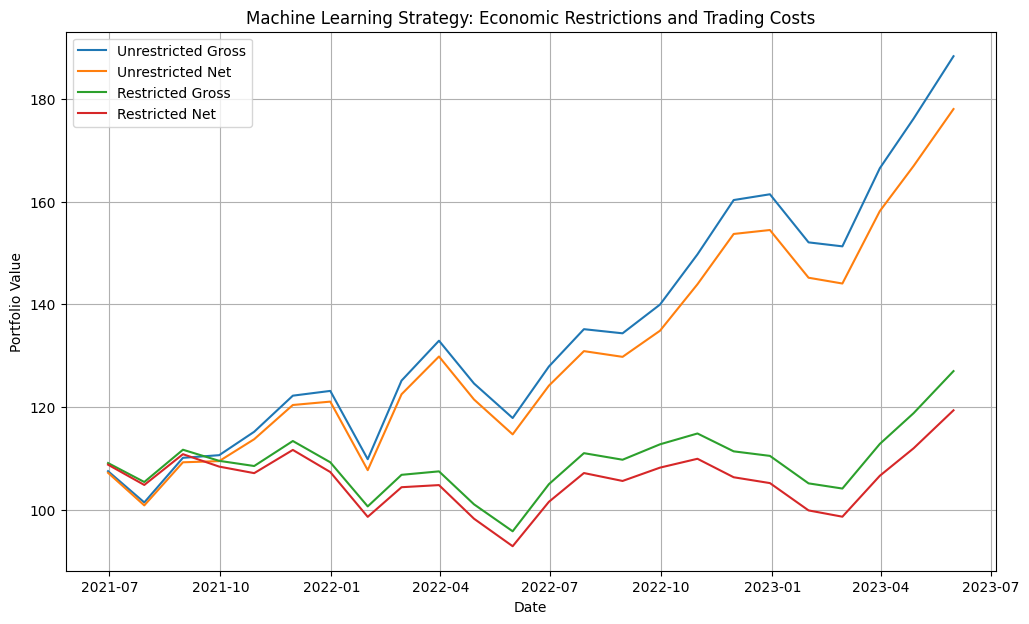

In [49]:
plt.figure(figsize=(12, 7))

plt.plot(
    comparison.index,
    comparison["Unrestricted Gross Equity"],
    label="Unrestricted Gross"
)

plt.plot(
    comparison.index,
    comparison["Unrestricted Net Equity"],
    label="Unrestricted Net"
)

plt.plot(
    comparison.index,
    comparison["Restricted Gross Equity"],
    label="Restricted Gross"
)

plt.plot(
    comparison.index,
    comparison["Restricted Net Equity"],
    label="Restricted Net"
)

plt.title(
    "Machine Learning Strategy: "
    "Economic Restrictions and Trading Costs"
)

plt.xlabel("Date")
plt.ylabel("Portfolio Value")

plt.legend()
plt.grid()

plt.show()

### Interpretation of the Cumulative Portfolio Performance

The cumulative portfolio value plot compares the performance of the unrestricted and economically restricted strategies before and after transaction costs.

The **unrestricted portfolio** achieves the highest final portfolio value, both on a gross and net basis. However, the difference between its gross and net performance shows the impact of transaction costs generated by portfolio turnover.

The **restricted portfolio** produces lower overall returns but follows a relatively less extreme performance path. The gap between its gross and net portfolio values also reflects the effect of its trading activity and transaction costs.

Overall, the graph highlights an important distinction between **gross performance and economically implementable performance**. A strategy that performs well before costs may experience a meaningful reduction in realised returns once turnover and trading frictions are incorporated.

In [50]:
print(results)

                        Unrestricted Gross  Unrestricted Net  \
Annual Return                     0.372392          0.334368   
Annual Volatility                 0.214054          0.213622   
Sharpe                            1.739708          1.565235   
Max Drawdown                     -0.113334         -0.116846   
Average Monthly Return            0.028551          0.026147   

                        Restricted Gross  Restricted Net  
Annual Return                   0.126904        0.092486  
Annual Volatility               0.179370        0.179025  
Sharpe                          0.707497        0.516607  
Max Drawdown                   -0.155157       -0.168078  
Average Monthly Return          0.011275        0.008666  


### Interpretation of Portfolio Performance Metrics

The performance summary shows that the **unrestricted portfolio outperforms the economically restricted portfolio across most return-based and risk-adjusted measures**.

The unrestricted portfolio achieves a gross annual return of approximately **37.24%**, compared with **12.69%** for the restricted portfolio. After incorporating transaction costs, the unrestricted strategy still produces a substantially higher annual return of **33.44%**, compared with **9.25%** for the restricted strategy.

The unrestricted portfolio also achieves the higher Sharpe ratio, with a net Sharpe ratio of approximately **1.57**, compared with **0.52** for the restricted portfolio. This indicates that, over this evaluation period, the higher returns of the unrestricted strategy more than compensate for its higher volatility.

However, the unrestricted portfolio is also more volatile, with annual volatility of approximately **21.4%**, compared with approximately **17.9%** for the restricted portfolio. The restricted portfolio therefore achieves lower risk in terms of return variability, but this reduction in volatility is accompanied by a substantial decline in returns.

The restricted portfolio also experiences a larger maximum drawdown after transaction costs (**-16.81%**) than the unrestricted portfolio (**-11.68%**). Thus, the economic restrictions do not appear to improve downside performance during this period.

Overall, the results suggest that, in this implementation and build-period sample, the liquidity and volatility restrictions **reduce the gross and net economic performance of the machine learning strategy**. Although the restricted portfolio has lower volatility, the reduction in risk is not sufficient to offset its substantially lower returns.

Importantly, these results are based on the build-period expanding-window evaluation. A separate holdout analysis is therefore required to determine whether these findings remain stable when evaluated on previously unseen data.

In [51]:
print("Unrestricted average turnover:",
      unrestricted_turnover.mean())

print("Restricted average turnover:",
      restricted_turnover.mean())

Unrestricted average turnover: 0.751388888888889
Restricted average turnover: 0.8152777777777779


### Turnover Comparison

The average turnover of both portfolios is reported to compare their trading intensity.

A higher turnover indicates that a larger proportion of the portfolio must be traded when the strategy is rebalanced, leading to potentially higher transaction costs.

The unrestricted portfolio and restricted portfolio are compared to determine whether the liquidity and volatility restrictions lead to more stable portfolio holdings. This is particularly important because a restricted strategy may reduce exposure to difficult-to-trade stocks but can still generate high turnover if the composition of the eligible investment universe changes substantially from month to month.

## Expanding-Window Holdout Evaluation

After evaluating the strategy during the build period, we test its performance on a separate **holdout period consisting of data not used in the initial model-development analysis**.

For each holdout month, the neural network is retrained using **all observations available strictly before that month**. This creates an expanding training window as time progresses.

The process is:

1. Use all historical data available before the prediction month.
2. Fit the feature scaler using only the training data.
3. Train the neural network.
4. Generate predictions for all stocks in the current holdout month.
5. Repeat for each subsequent holdout month.

This approach ensures that predictions are always generated without using information from the future, while allowing the model to incorporate newly available historical data as the evaluation period progresses.

The resulting holdout predictions provide a more independent test of whether the machine learning strategy's predictive and economic performance extends beyond the original build period.

In [52]:
holdout_predictions = []

holdout_months = sorted(
    holdout_data["date"].unique()
)

for prediction_month in holdout_months:

    # Training data is strictly before this month
    train = model_data[
        model_data["date"] < prediction_month
    ].copy()

    test = holdout_data[
        holdout_data["date"] == prediction_month
    ].copy()

    X_train = train[features]
    y_train = train["target_return"]

    X_test = test[features]

    # Scale using training data only
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)

    X_test_scaled = scaler.transform(X_test)

    # Train model
    model = create_model()

    model.fit(
        X_train_scaled,
        y_train
    )

    # Predict
    test["prediction"] = model.predict(
        X_test_scaled
    )

    holdout_predictions.append(test)

    print(
        f"{prediction_month.strftime('%Y-%m')} | "
        f"Train: {len(train)} | "
        f"Predicted: {len(test)}"
    )

2023-06 | Train: 17570 | Predicted: 470
2023-07 | Train: 18040 | Predicted: 470
2023-08 | Train: 18510 | Predicted: 470
2023-09 | Train: 18980 | Predicted: 472
2023-10 | Train: 19452 | Predicted: 473
2023-11 | Train: 19925 | Predicted: 478
2023-12 | Train: 20403 | Predicted: 478
2024-01 | Train: 20881 | Predicted: 479
2024-02 | Train: 21360 | Predicted: 480
2024-03 | Train: 21840 | Predicted: 480
2024-04 | Train: 22320 | Predicted: 480
2024-05 | Train: 22800 | Predicted: 481


In [54]:
holdout_predictions_df = pd.concat(
    holdout_predictions,
    ignore_index=True
)

print(holdout_predictions_df.shape)

holdout_predictions_df[
    ["date", "ticker", "prediction", "target_return"]
].head()

(5711, 27)


,date,ticker,prediction,target_return
0,2023-06-30,360ONE,0.029151,0.146484
1,2023-06-30,3MINDIA,0.080321,0.070702
2,2023-06-30,AARTIIND,0.039219,-0.071684
3,2023-06-30,AAVAS,0.059211,0.007710
4,2023-06-30,ABB,0.014906,0.029347


In [55]:
holdout_ic = (
    holdout_predictions_df
    .groupby("date")
    .apply(
        lambda x: x["prediction"].corr(
            x["target_return"],
            method="spearman"
        )
    )
)

print("Average holdout IC:", holdout_ic.mean())

print("\nMonthly IC values:")
print(holdout_ic)

Average holdout IC: 0.01746692582825479

Monthly IC values:
date
2023-06-30   -0.006880
2023-07-31    0.066388
2023-08-31   -0.075514
2023-09-29    0.022504
2023-10-31    0.127529
2023-11-30   -0.135199
2023-12-29    0.261031
2024-01-31   -0.054217
2024-02-29   -0.089479
2024-03-28    0.126374
2024-04-30   -0.058009
2024-05-31    0.025073
dtype: float64


### Interpretation of Holdout Information Coefficient Results

The average Information Coefficient during the holdout period is approximately **0.0175**, which is slightly higher than the average IC observed during the build-period evaluation.

This indicates a weak positive average relationship between the neural network's predicted returns and the realised next-month returns in the unseen holdout sample.

However, the individual monthly IC values vary substantially. Several months show strongly positive predictive relationships, such as **December 2023**, while other months show negative IC values, indicating that the model's stock rankings were sometimes inversely related to realised returns.

Therefore, although the average holdout IC is positive, the results suggest that the predictive performance of the model is **not consistently stable across individual months**. The positive average appears to be influenced by a small number of months with relatively strong positive IC values.

The next step is to translate these holdout predictions into portfolios and evaluate whether this weak and variable predictive ability produces economically meaningful investment performance after portfolio restrictions and transaction costs.

In [56]:
holdout_unrestricted = (
    holdout_predictions_df.copy()
)

holdout_unrestricted["prediction_rank"] = (
    holdout_unrestricted
    .groupby("date")["prediction"]
    .rank(
        ascending=False,
        method="first"
    )
)

holdout_unrestricted_portfolio = (
    holdout_unrestricted[
        holdout_unrestricted["prediction_rank"]
        <= N_STOCKS
    ]
    .copy()
)

holdout_unrestricted_portfolio["weight"] = (
    1
    /
    holdout_unrestricted_portfolio
    .groupby("date")["ticker"]
    .transform("count")
)

In [57]:
holdout_restricted = (
    holdout_predictions_df.copy()
)

# Remove least liquid 30%
holdout_restricted["liquidity_rank"] = (
    holdout_restricted
    .groupby("date")["adv_3m"]
    .rank(pct=True)
)

holdout_restricted = (
    holdout_restricted[
        holdout_restricted["liquidity_rank"]
        >= 0.30
    ]
    .copy()
)

# Remove highest volatility decile
holdout_restricted["volatility_rank"] = (
    holdout_restricted
    .groupby("date")["vol_3m"]
    .rank(pct=True)
)

holdout_restricted = (
    holdout_restricted[
        holdout_restricted["volatility_rank"]
        <= 0.90
    ]
    .copy()
)

# Rank predictions
holdout_restricted["prediction_rank"] = (
    holdout_restricted
    .groupby("date")["prediction"]
    .rank(
        ascending=False,
        method="first"
    )
)

# Top 30
holdout_restricted_portfolio = (
    holdout_restricted[
        holdout_restricted["prediction_rank"]
        <= N_STOCKS
    ]
    .copy()
)

# Equal weights
holdout_restricted_portfolio["weight"] = (
    1
    /
    holdout_restricted_portfolio
    .groupby("date")["ticker"]
    .transform("count")
)

In [58]:
holdout_unrestricted_returns = (
    holdout_unrestricted_portfolio
    .groupby("date")
    .apply(
        lambda x: np.sum(
            x["weight"]
            * x["target_return"]
        )
    )
    .rename("gross_return")
    .to_frame()
)

holdout_restricted_returns = (
    holdout_restricted_portfolio
    .groupby("date")
    .apply(
        lambda x: np.sum(
            x["weight"]
            * x["target_return"]
        )
    )
    .rename("gross_return")
    .to_frame()
)

In [59]:
holdout_unrestricted_returns["turnover"] = (
    calculate_turnover(
        holdout_unrestricted_portfolio
    )
)

holdout_restricted_returns["turnover"] = (
    calculate_turnover(
        holdout_restricted_portfolio
    )
)

In [60]:
holdout_unrestricted_returns["trading_cost"] = (
    holdout_unrestricted_returns["turnover"]
    * ROUND_TRIP_COST
)

holdout_unrestricted_returns["net_return"] = (
    holdout_unrestricted_returns["gross_return"]
    - holdout_unrestricted_returns["trading_cost"]
)

In [61]:
holdout_restricted_returns["trading_cost"] = (
    holdout_restricted_returns["turnover"]
    * ROUND_TRIP_COST
)

holdout_restricted_returns["net_return"] = (
    holdout_restricted_returns["gross_return"]
    - holdout_restricted_returns["trading_cost"]
)

In [62]:
holdout_results = pd.DataFrame({

    "Unrestricted Gross":
        performance_metrics(
            holdout_unrestricted_returns[
                "gross_return"
            ]
        ),

    "Unrestricted Net":
        performance_metrics(
            holdout_unrestricted_returns[
                "net_return"
            ]
        ),

    "Restricted Gross":
        performance_metrics(
            holdout_restricted_returns[
                "gross_return"
            ]
        ),

    "Restricted Net":
        performance_metrics(
            holdout_restricted_returns[
                "net_return"
            ]
        )
})

holdout_results

,Unrestricted Gross,Unrestricted Net,Restricted Gross,Restricted Net
Annual Return,0.834136,0.783725,0.886158,0.831161
Annual Volatility,0.205903,0.205967,0.208299,0.208142
Sharpe,4.051114,3.805102,4.254267,3.993241
Max Drawdown,-0.028149,-0.030603,-0.036238,-0.038585
Average Monthly Return,0.053387,0.050952,0.055874,0.053278


### Interpretation of Expanding-Window Holdout Portfolio Results

The expanding-window holdout results show substantially stronger portfolio performance than the build-period evaluation. Both strategies generate high gross and net returns, indicating that the model's predictions produced economically favourable portfolio outcomes during this particular holdout period.

The **restricted portfolio outperforms the unrestricted portfolio** on both gross and net annual returns. After transaction costs, the restricted strategy achieves an annual return of approximately **83.12%**, compared with **78.37%** for the unrestricted strategy.

The restricted portfolio also achieves a higher net Sharpe ratio of approximately **3.99**, compared with **3.81** for the unrestricted portfolio. This suggests that the restricted strategy generated slightly better risk-adjusted performance during the holdout period.

However, the restricted portfolio has marginally higher volatility and a slightly larger maximum drawdown. Its superior Sharpe ratio is therefore primarily driven by its higher returns rather than lower risk.

These results suggest that, during the expanding-window holdout period, applying liquidity and volatility restrictions improved the realised economic performance of the machine learning strategy. This differs from the build-period results, where the unrestricted portfolio performed substantially better.

Because the model is retrained each month in this expanding-window experiment, these results should be interpreted as a **dynamic out-of-sample evaluation** rather than a completely fixed model test. A stricter frozen-model holdout evaluation is therefore conducted next to examine whether the observed performance remains when the model is trained only once and not updated during the holdout period.

In [63]:
holdout_comparison = pd.DataFrame({

    "Unrestricted Gross":
        holdout_unrestricted_returns[
            "gross_return"
        ],

    "Unrestricted Net":
        holdout_unrestricted_returns[
            "net_return"
        ],

    "Restricted Gross":
        holdout_restricted_returns[
            "gross_return"
        ],

    "Restricted Net":
        holdout_restricted_returns[
            "net_return"
        ]
})

for column in holdout_comparison.columns:

    holdout_comparison[
        column + " Equity"
    ] = (
        100
        * (1 + holdout_comparison[column])
        .cumprod()
    )

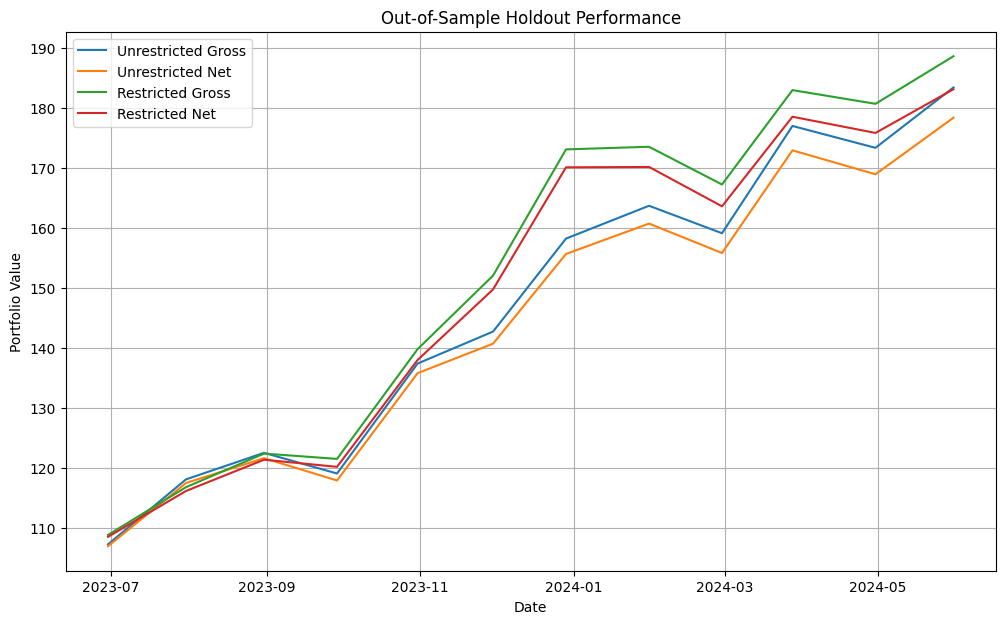

In [64]:
plt.figure(figsize=(12, 7))

plt.plot(
    holdout_comparison.index,
    holdout_comparison[
        "Unrestricted Gross Equity"
    ],
    label="Unrestricted Gross"
)

plt.plot(
    holdout_comparison.index,
    holdout_comparison[
        "Unrestricted Net Equity"
    ],
    label="Unrestricted Net"
)

plt.plot(
    holdout_comparison.index,
    holdout_comparison[
        "Restricted Gross Equity"
    ],
    label="Restricted Gross"
)

plt.plot(
    holdout_comparison.index,
    holdout_comparison[
        "Restricted Net Equity"
    ],
    label="Restricted Net"
)

plt.title(
    "Out-of-Sample Holdout Performance"
)

plt.xlabel("Date")
plt.ylabel("Portfolio Value")

plt.legend()
plt.grid()

plt.show()

### Interpretation of Out-of-Sample Holdout Performance

The cumulative performance graph shows that both portfolios generated strong gains during the holdout period, although their relative performance changed over time.

The **restricted portfolio** generally finishes with the highest gross portfolio value, while its net performance also remains competitive after transaction costs. This is consistent with the performance metrics, where the restricted strategy achieved slightly higher annual returns and Sharpe ratios during the expanding-window holdout period.

Both strategies experience temporary declines during the evaluation period, particularly around early 2024, but subsequently recover and finish the holdout period at substantially higher portfolio values than at the beginning.

The graph also highlights the effect of transaction costs. In both strategies, the net portfolio value remains below the corresponding gross portfolio value, with the gap representing the cumulative impact of trading costs.

Overall, the holdout results suggest that the economic restrictions improved portfolio performance during this particular out-of-sample period. However, because the model is retrained and updated each month, these results reflect the performance of an **adaptive expanding-window strategy**. A stricter frozen-model test is therefore required to determine whether similar results can be achieved without continuously updating the model.

In [65]:
print(holdout_results)

print("\nHoldout IC:", holdout_ic.mean())

print(
    "\nUnrestricted turnover:",
    holdout_unrestricted_returns["turnover"].mean()
)

print(
    "Restricted turnover:",
    holdout_restricted_returns["turnover"].mean()
)

                        Unrestricted Gross  Unrestricted Net  \
Annual Return                     0.834136          0.783725   
Annual Volatility                 0.205903          0.205967   
Sharpe                            4.051114          3.805102   
Max Drawdown                     -0.028149         -0.030603   
Average Monthly Return            0.053387          0.050952   

                        Restricted Gross  Restricted Net  
Annual Return                   0.886158        0.831161  
Annual Volatility               0.208299        0.208142  
Sharpe                          4.254267        3.993241  
Max Drawdown                   -0.036238       -0.038585  
Average Monthly Return          0.055874        0.053278  

Holdout IC: 0.01746692582825479

Unrestricted turnover: 0.7611111111111111
Restricted turnover: 0.8111111111111112


### Summary of Expanding-Window Holdout Results

The expanding-window holdout results show strong portfolio performance despite the model having only a weak positive predictive signal. The holdout IC of **0.0175** indicates that the relationship between predicted and realised stock returns remains positive on average, although relatively weak.

Both portfolios generated high returns during the holdout period. The **restricted portfolio performed slightly better**, achieving a net annual return of **83.12%** and a net Sharpe ratio of **3.99**, compared with **78.37%** and **3.81** for the unrestricted portfolio.

The restricted strategy, however, also had slightly higher turnover (**81.11%**) than the unrestricted strategy (**76.11%**). Therefore, its superior performance cannot be attributed to lower trading activity or lower transaction costs.

Overall, these results suggest that the liquidity and volatility restrictions improved the economic performance of the strategy during this expanding-window holdout period. However, the relatively weak IC and high portfolio returns also indicate that performance should be interpreted cautiously, as realised portfolio outcomes can be influenced by the specific market conditions and relatively short evaluation period.

The next experiment therefore applies a **frozen-model holdout test**, in which the model is trained only on the build period and is not retrained during the holdout period.

In [66]:
benchmark = (
    holdout_predictions_df
    .groupby("date")["target_return"]
    .mean()
    .rename("benchmark_return")
    .to_frame()
)

benchmark.head()

,benchmark_return
date,
2023-06-30,0.071468
2023-07-31,0.047696
2023-08-31,0.034638
2023-09-29,-0.023580
2023-10-31,0.092724


In [67]:
benchmark_metrics = performance_metrics(
    benchmark["benchmark_return"]
)

print(benchmark_metrics)

Annual Return             0.615111
Annual Volatility         0.144075
Sharpe                    4.269388
Max Drawdown             -0.023580
Average Monthly Return    0.041530
dtype: float64


In [68]:
holdout_comparison["Benchmark"] = (
    benchmark["benchmark_return"]
)

In [69]:
holdout_comparison["Benchmark Equity"] = (
    100 *
    (1 + holdout_comparison["Benchmark"])
    .cumprod()
)

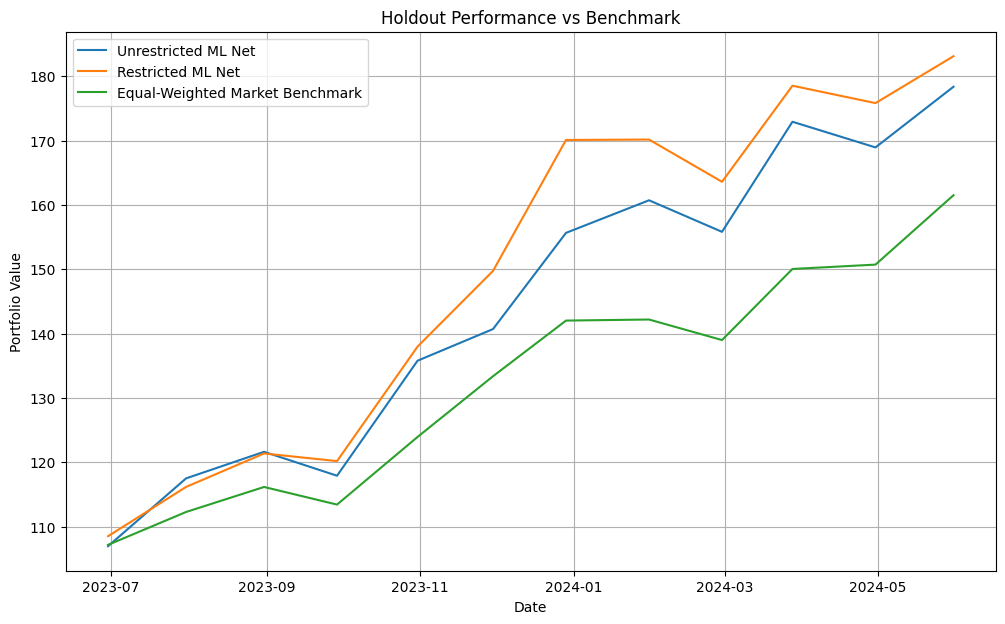

In [70]:
plt.figure(figsize=(12, 7))

plt.plot(
    holdout_comparison.index,
    holdout_comparison["Unrestricted Net Equity"],
    label="Unrestricted ML Net"
)

plt.plot(
    holdout_comparison.index,
    holdout_comparison["Restricted Net Equity"],
    label="Restricted ML Net"
)

plt.plot(
    holdout_comparison.index,
    holdout_comparison["Benchmark Equity"],
    label="Equal-Weighted Market Benchmark"
)

plt.title("Holdout Performance vs Benchmark")

plt.xlabel("Date")
plt.ylabel("Portfolio Value")

plt.legend()
plt.grid()

plt.show()

### Comparison with the Equal-Weighted Market Benchmark

The holdout performance is also compared with an **equal-weighted market benchmark**, which represents the return obtained by investing equally across the available stocks without using the machine learning predictions.

Both machine learning portfolios outperform the benchmark over the holdout period. The **restricted ML portfolio achieves the highest final portfolio value**, followed by the unrestricted ML portfolio, while the equal-weighted benchmark finishes considerably lower.

This comparison suggests that the portfolio performance is not solely explained by a general rise in the underlying market during the holdout period. Both ML-based strategies generated returns above those achieved by simply holding the available stocks with equal weights.

The restricted strategy's stronger performance is particularly notable because its advantage remains after transaction costs are deducted. However, the holdout period is relatively short, so these results should be interpreted as evidence from this specific evaluation period rather than definitive proof of persistent long-term outperformance.

## Measuring Excess Returns Relative to the Benchmark

While comparing cumulative portfolio values provides a visual indication of outperformance, we also directly calculate the **excess return** of each machine learning strategy relative to the equal-weighted market benchmark.

For each month:

$$
R^{excess}_{t}
=
R^{ML,net}_{t}
-
R^{benchmark}_{t}
$$

where $R^{ML,net}_{t}$ is the transaction-cost-adjusted return of the machine learning portfolio.

Positive excess returns indicate that the strategy outperformed the benchmark during that month, while negative values indicate underperformance.

The same performance metrics are then calculated using these excess returns to evaluate whether the unrestricted and restricted strategies generated returns above the benchmark on both an absolute and risk-adjusted basis.

In [71]:
excess_returns = pd.DataFrame()

excess_returns["Unrestricted Excess"] = (
    holdout_unrestricted_returns["net_return"]
    - benchmark["benchmark_return"]
)

excess_returns["Restricted Excess"] = (
    holdout_restricted_returns["net_return"]
    - benchmark["benchmark_return"]
)

excess_results = pd.DataFrame({

    "Unrestricted Excess":
        performance_metrics(
            excess_returns["Unrestricted Excess"]
        ),

    "Restricted Excess":
        performance_metrics(
            excess_returns["Restricted Excess"]
        )
})

print(excess_results)

                        Unrestricted Excess  Restricted Excess
Annual Return                      0.112904           0.145322
Annual Volatility                  0.111284           0.100418
Sharpe                             1.014552           1.447176
Max Drawdown                      -0.042913          -0.054283
Average Monthly Return             0.009422           0.011748


## Frozen Model Holdout Test

The previous holdout evaluation used an expanding-window approach, where the model was retrained as new data became available. To conduct a stricter out-of-sample test, we now train the neural network **only once** using the complete build period.

The model is trained using data available up to May 2023, while the entire period from June 2023 onward remains unseen during training.

Feature scaling is also fitted exclusively on the build-period data and then applied to the holdout observations. This ensures that no information from the holdout period influences either feature normalization or model training.

Unlike the expanding-window approach, the model is **not retrained or updated** during the holdout period. Its parameters remain fixed throughout the test period.

This frozen-model experiment therefore provides a stricter measure of generalisation: it tests whether the relationships learned during the build period remain useful for predicting stock returns in a completely unseen future period.

In [72]:
# Training data: everything up to May 2023
X_train = build_data[features]
y_train = build_data["target_return"]

# Holdout features
X_holdout = holdout_data[features]

# Scale using training data only
frozen_scaler = StandardScaler()

X_train_scaled = frozen_scaler.fit_transform(
    X_train
)

X_holdout_scaled = frozen_scaler.transform(
    X_holdout
)

# Train one model
frozen_model = create_model()

frozen_model.fit(
    X_train_scaled,
    y_train
)

print("Frozen model trained.")

Frozen model trained.


In [73]:
frozen_holdout = holdout_data.copy()

frozen_holdout["prediction"] = (
    frozen_model.predict(
        X_holdout_scaled
    )
)

frozen_holdout[
    ["date", "ticker", "prediction", "target_return"]
].head()

,date,ticker,prediction,target_return
45,2023-06-30,360ONE,0.029151,0.146484
46,2023-07-31,360ONE,-0.000286,-0.065753
47,2023-08-31,360ONE,0.057922,0.030266
48,2023-09-29,360ONE,0.034158,0.045808
49,2023-10-31,360ONE,0.021496,0.089792


In [74]:
frozen_ic = (
    frozen_holdout
    .groupby("date")
    .apply(
        lambda x: x["prediction"].corr(
            x["target_return"],
            method="spearman"
        )
    )
)

print("Frozen holdout IC:", frozen_ic.mean())

Frozen holdout IC: 0.0022390416741750532


### Interpretation of Frozen Holdout Information Coefficient

The frozen model produces an average holdout Information Coefficient of approximately **0.0022**, which is very close to zero.

This indicates that, once the neural network is trained only on the build-period data and its parameters are kept fixed, there is almost no consistent cross-sectional relationship between its predicted returns and the realised returns in the holdout period.

The frozen-model IC is also substantially lower than the expanding-window holdout IC of approximately **0.0175**. This suggests that the predictive relationships captured by the model may not remain stable over time and that periodic retraining may be important for adapting to changing market conditions.

Overall, the frozen holdout result provides a stricter and less favourable assessment of the model's standalone predictive ability. The subsequent portfolio analysis therefore examines whether a weak stock-level predictive signal can nevertheless produce economically meaningful returns after ranking, portfolio construction, and transaction costs are considered.

In [75]:
frozen_unrestricted = frozen_holdout.copy()

frozen_unrestricted["prediction_rank"] = (
    frozen_unrestricted
    .groupby("date")["prediction"]
    .rank(
        ascending=False,
        method="first"
    )
)

frozen_unrestricted_portfolio = (
    frozen_unrestricted[
        frozen_unrestricted["prediction_rank"]
        <= N_STOCKS
    ]
    .copy()
)

frozen_unrestricted_portfolio["weight"] = (
    1
    /
    frozen_unrestricted_portfolio
    .groupby("date")["ticker"]
    .transform("count")
)

In [76]:
frozen_restricted = frozen_holdout.copy()

# Liquidity restriction
frozen_restricted["liquidity_rank"] = (
    frozen_restricted
    .groupby("date")["adv_3m"]
    .rank(pct=True)
)

frozen_restricted = (
    frozen_restricted[
        frozen_restricted["liquidity_rank"] >= 0.30
    ]
    .copy()
)

# Volatility restriction
frozen_restricted["volatility_rank"] = (
    frozen_restricted
    .groupby("date")["vol_3m"]
    .rank(pct=True)
)

frozen_restricted = (
    frozen_restricted[
        frozen_restricted["volatility_rank"] <= 0.90
    ]
    .copy()
)

# Prediction ranking
frozen_restricted["prediction_rank"] = (
    frozen_restricted
    .groupby("date")["prediction"]
    .rank(
        ascending=False,
        method="first"
    )
)

frozen_restricted_portfolio = (
    frozen_restricted[
        frozen_restricted["prediction_rank"]
        <= N_STOCKS
    ]
    .copy()
)

frozen_restricted_portfolio["weight"] = (
    1
    /
    frozen_restricted_portfolio
    .groupby("date")["ticker"]
    .transform("count")
)

In [77]:
frozen_unrestricted_returns = (
    frozen_unrestricted_portfolio
    .groupby("date")
    .apply(
        lambda x: np.sum(
            x["weight"]
            * x["target_return"]
        )
    )
    .rename("gross_return")
    .to_frame()
)

frozen_restricted_returns = (
    frozen_restricted_portfolio
    .groupby("date")
    .apply(
        lambda x: np.sum(
            x["weight"]
            * x["target_return"]
        )
    )
    .rename("gross_return")
    .to_frame()
)

In [78]:
frozen_unrestricted_returns["turnover"] = (
    calculate_turnover(
        frozen_unrestricted_portfolio
    )
)

frozen_restricted_returns["turnover"] = (
    calculate_turnover(
        frozen_restricted_portfolio
    )
)

In [79]:
for returns_df in [
    frozen_unrestricted_returns,
    frozen_restricted_returns
]:
    
    returns_df["trading_cost"] = (
        returns_df["turnover"]
        * ROUND_TRIP_COST
    )
    
    returns_df["net_return"] = (
        returns_df["gross_return"]
        - returns_df["trading_cost"]
    )

In [80]:
frozen_benchmark = (
    frozen_holdout
    .groupby("date")["target_return"]
    .mean()
    .rename("benchmark_return")
)

In [81]:
frozen_excess = pd.DataFrame()

frozen_excess["Unrestricted Excess"] = (
    frozen_unrestricted_returns["net_return"]
    - frozen_benchmark
)

frozen_excess["Restricted Excess"] = (
    frozen_restricted_returns["net_return"]
    - frozen_benchmark
)

In [82]:
frozen_results = pd.DataFrame({

    "Unrestricted Net":
        performance_metrics(
            frozen_unrestricted_returns[
                "net_return"
            ]
        ),

    "Restricted Net":
        performance_metrics(
            frozen_restricted_returns[
                "net_return"
            ]
        ),

    "Unrestricted Excess":
        performance_metrics(
            frozen_excess[
                "Unrestricted Excess"
            ]
        ),

    "Restricted Excess":
        performance_metrics(
            frozen_excess[
                "Restricted Excess"
            ]
        )
})

print(frozen_results)

print("\nFrozen Holdout IC:")
print(frozen_ic.mean())

print("\nAverage Turnover:")
print(
    "Unrestricted:",
    frozen_unrestricted_returns[
        "turnover"
    ].mean()
)

print(
    "Restricted:",
    frozen_restricted_returns[
        "turnover"
    ].mean()
)

                        Unrestricted Net  Restricted Net  Unrestricted Excess  \
Annual Return                   0.650925        0.690679             0.023089   
Annual Volatility               0.178265        0.177702             0.098312   
Sharpe                          3.651450        3.886735             0.234857   
Max Drawdown                   -0.021370       -0.047577            -0.080588   
Average Monthly Return          0.043795        0.045897             0.002264   

                        Restricted Excess  
Annual Return                    0.051826  
Annual Volatility                0.062195  
Sharpe                           0.833289  
Max Drawdown                    -0.027817  
Average Monthly Return           0.004367  

Frozen Holdout IC:
0.0022390416741750532

Average Turnover:
Unrestricted: 0.7500000000000001
Restricted: 0.8472222222222223


### Interpretation of Frozen Holdout Portfolio Results

Despite the frozen model having an Information Coefficient close to zero (**0.0022**), both portfolios generated strong absolute returns during the holdout period. The restricted portfolio achieved a slightly higher net annual return (**69.07%**) and net Sharpe ratio (**3.89**) than the unrestricted portfolio (**65.09%** annual return and **3.65** Sharpe ratio).

However, the comparison with the benchmark provides a more important perspective. The unrestricted portfolio generated only a **2.31% annualised excess return**, while the restricted portfolio generated a higher **5.18% annualised excess return**. This indicates that much of the strong absolute performance occurred alongside favourable overall market performance rather than being entirely attributable to the model's predictive ability.

The excess-return Sharpe ratios are also substantially lower than the absolute-return Sharpe ratios, particularly for the unrestricted strategy. This further suggests that the high absolute Sharpe ratios should not be interpreted as strong evidence of a powerful stock-selection signal.

The restricted portfolio has higher average turnover (**84.72%**) than the unrestricted portfolio (**75.00%**), meaning that its stronger excess performance is achieved despite greater trading activity and potentially greater sensitivity to transaction costs.

Overall, the frozen holdout results provide a more cautious interpretation of the strategy. Although both portfolios perform strongly in absolute terms and the restricted portfolio shows somewhat better benchmark-adjusted performance, the near-zero frozen IC suggests that the model's stock-level predictive signal does not generalise strongly across time. The results therefore indicate that portfolio performance can remain attractive even when the underlying predictive relationship is weak, but this performance should be interpreted relative to market conditions and benchmark returns rather than in absolute terms alone.

In [83]:
cost_levels = {
    "16 bps": 0.0016,
    "32 bps": 0.0032,
    "50 bps": 0.0050,
    "100 bps": 0.0100
}

cost_results = []

for cost_name, cost in cost_levels.items():

    # Unrestricted
    unrestricted_net = (
        frozen_unrestricted_returns["gross_return"]
        - frozen_unrestricted_returns["turnover"] * cost
    )

    # Restricted
    restricted_net = (
        frozen_restricted_returns["gross_return"]
        - frozen_restricted_returns["turnover"] * cost
    )

    unrestricted_excess = (
        unrestricted_net
        - frozen_benchmark
    )

    restricted_excess = (
        restricted_net
        - frozen_benchmark
    )

    cost_results.append({

        "Cost Level": cost_name,

        "Unrestricted Net Sharpe":
            performance_metrics(unrestricted_net)["Sharpe"],

        "Restricted Net Sharpe":
            performance_metrics(restricted_net)["Sharpe"],

        "Unrestricted Excess Sharpe":
            performance_metrics(
                unrestricted_excess
            )["Sharpe"],

        "Restricted Excess Sharpe":
            performance_metrics(
                restricted_excess
            )["Sharpe"]

    })

cost_results = pd.DataFrame(cost_results)

cost_results

,Cost Level,Unrestricted Net Sharpe,Restricted Net Sharpe,Unrestricted Excess Sharpe,Restricted Excess Sharpe
0,16 bps,3.778337,4.037602,0.385281,1.110570
1,32 bps,3.651450,3.886735,0.234857,0.833289
2,50 bps,3.510447,3.719639,0.067840,0.526880
3,100 bps,3.128311,3.269784,-0.383894,-0.293852


### Interpretation of Transaction Cost Sensitivity

The transaction cost sensitivity analysis examines how the performance of both strategies changes as the assumed round-trip trading cost increases from **16 basis points to 100 basis points**.

As expected, the **net Sharpe ratios decline as transaction costs increase**, since both portfolios have relatively high turnover and therefore incur greater costs when rebalanced.

The restricted portfolio maintains a higher net Sharpe ratio than the unrestricted portfolio across all four cost assumptions. This suggests that the restricted strategy retains a slight advantage in absolute risk-adjusted performance even when trading costs become more severe.

However, the benchmark-adjusted results provide a more cautious interpretation. At lower transaction costs, both strategies generate positive excess Sharpe ratios, with the restricted portfolio performing substantially better. As costs increase to **100 basis points**, both excess Sharpe ratios become negative, indicating that neither strategy generates attractive benchmark-adjusted performance under sufficiently high trading costs.

Overall, the sensitivity analysis shows that the economic conclusions of the strategy depend significantly on the assumed level of transaction costs. The restricted portfolio appears more robust than the unrestricted portfolio across moderate cost levels, but neither strategy maintains positive benchmark-adjusted risk-adjusted performance under very high trading costs.

## Conclusion

This project implemented a neural-network-based stock selection strategy using cross-sectional financial and market characteristics to predict next-month stock returns. The model was evaluated through expanding-window testing, an independent holdout period, and a stricter frozen-model experiment.

Overall, the neural network demonstrated **weak standalone cross-sectional predictive ability**. The average Information Coefficient was positive but small during the build and expanding-window holdout periods, while the frozen out-of-sample IC was close to zero. This suggests that the predictive relationships learned by the model were not particularly strong or stable over time.

Despite this weak stock-level predictive signal, the portfolio results were more favourable. Translating the model predictions into portfolios generated strong absolute returns during the holdout period, although comparison with the equal-weighted benchmark showed that a substantial portion of this performance was associated with broader market conditions.

The economically restricted portfolio, which excluded relatively illiquid and highly volatile stocks before selecting the highest-ranked predictions, generally produced stronger **benchmark-adjusted and excess risk-adjusted performance** than the unrestricted portfolio. This advantage persisted across transaction-cost assumptions between **16 and 50 basis points**, although both strategies produced negative excess Sharpe ratios when costs increased to **100 basis points**.

Taken together, the results suggest that **economic constraints may add value primarily through portfolio construction rather than through improvements in the underlying predictive accuracy of the neural network**. A weak machine-learning signal can still produce useful portfolio outcomes when combined with ranking, diversification, liquidity considerations, volatility restrictions, and realistic transaction-cost analysis. However, the high turnover, sensitivity to transaction costs, short evaluation period, and near-zero frozen Information Coefficient indicate that the results should be interpreted cautiously and do not establish persistent predictive superiority.

Overall, the implementation highlights the importance of evaluating machine-learning investment strategies not only through statistical prediction metrics, but also through their **economic performance, benchmark-adjusted returns, trading frictions, and robustness under genuinely out-of-sample conditions**.